<a href="https://colab.research.google.com/github/25f2009371-oss/Deep-Learning-with-pytorch-My-notes-and-work-/blob/main/02_Pytorch_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#*Pytorch* WorkFlow


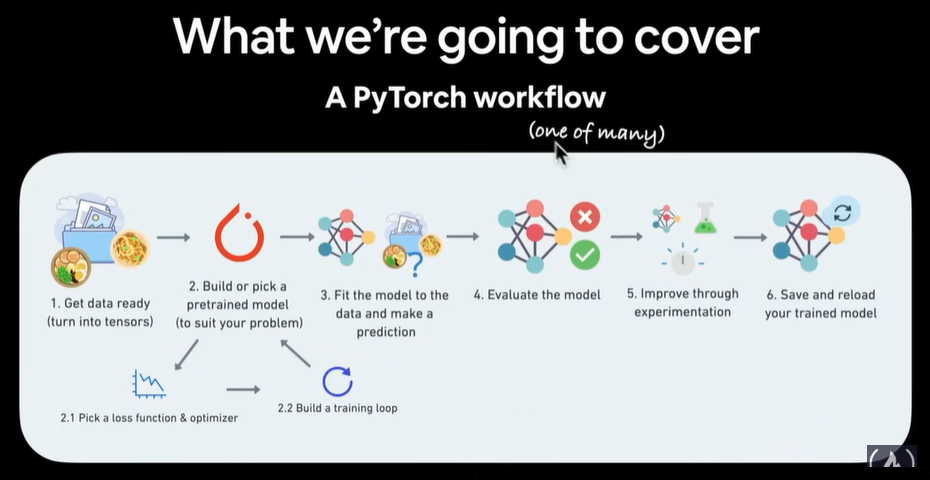

1. data prepare and load
2. build model
3. fitting the model to data training
4. make prediction and evaluate a model inference
5. moding and loading a model
6. putting it all together

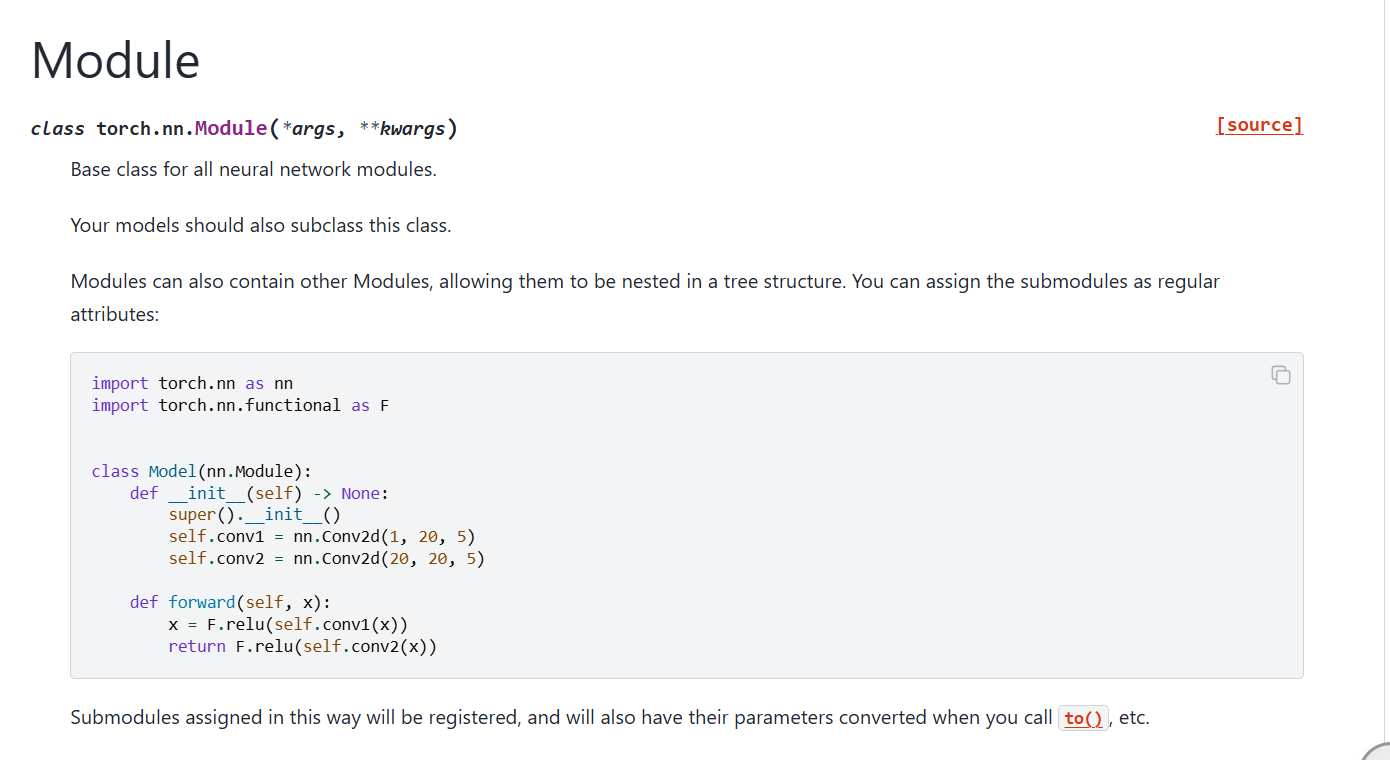


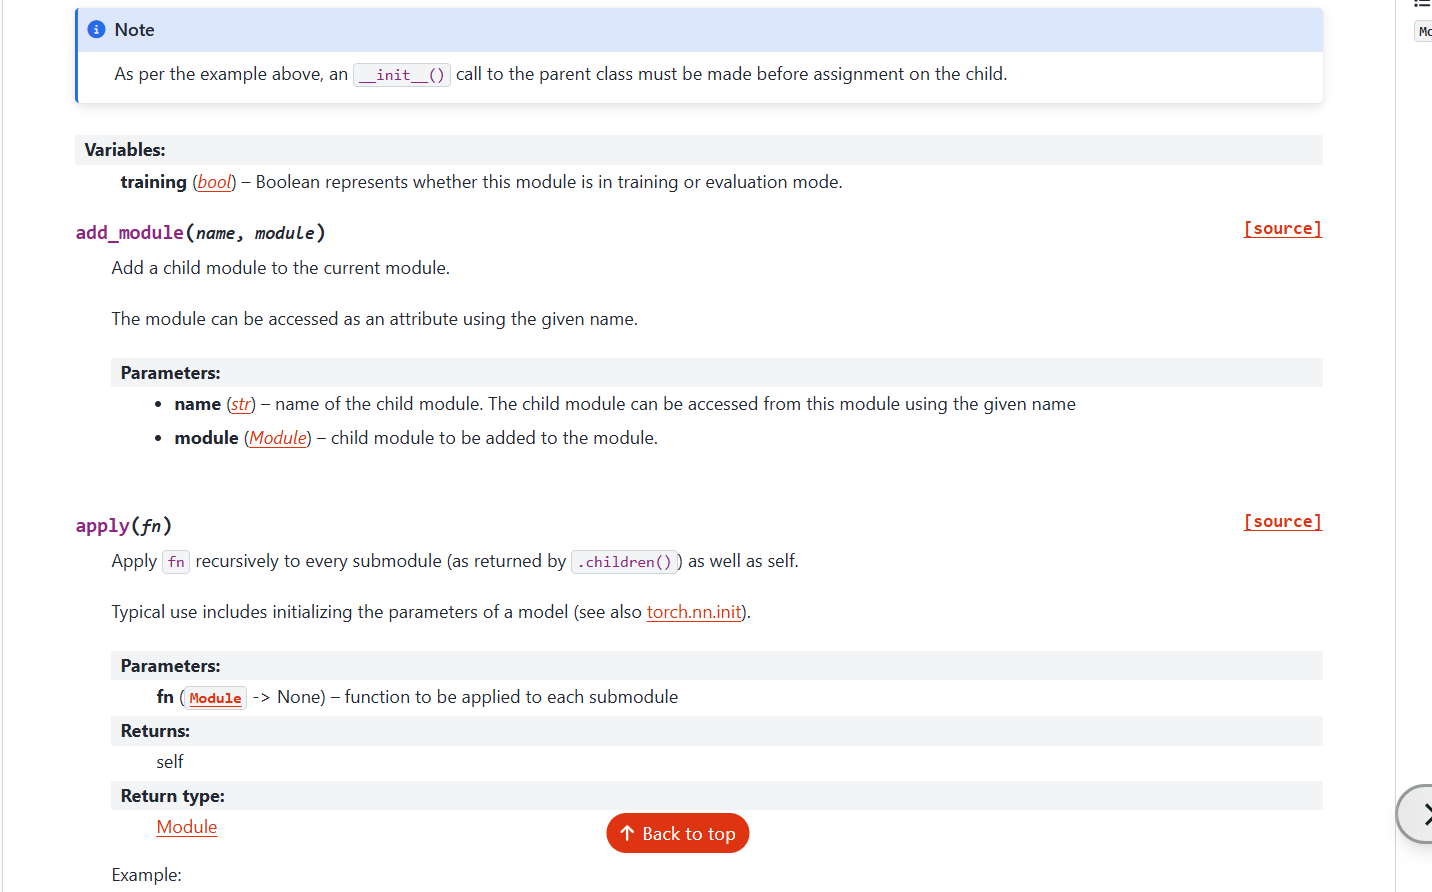

In [1]:
import torch
## nn contain all of pytorch building block of neural network
from torch import nn
import matplotlib.pyplot as plt

In [2]:
torch.__version__

'2.14.1+cpu'

# Data(preparing and loading)

data can be almost anything... in machine learnign

* Excel spreadsheet
* Images of any kind
* Videos
* Audios
* DNA
* Text

Machine leanring is a game of two parts:
1. Get data into numerical representation .
2. Build a model to learn patterns in that numerical representation.

To showcase this, lets create some *known* data using linear regression formula


we will use a linear regression formula to make a straith line with known parameters

In [3]:
#Create *known* parameters
weight=0.7895
bias=0.058563

#creating input points
start=0
end=1

X=torch.arange(start,end,0.02).unsqueeze(dim=1)
#creating functun
y=weight*X+bias ##basically we initialise our model here , in simple words my target is by seeing input and output my model learn and get best possible parameter of weight and bias so we can predict Y using input X


print(X[:10])
print("\n")
print(y[:10])


tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])


tensor([[0.0586],
        [0.0744],
        [0.0901],
        [0.1059],
        [0.1217],
        [0.1375],
        [0.1533],
        [0.1691],
        [0.1849],
        [0.2007]])


In [4]:
len(X),len(y)

(50, 50)

##Spilitting data into training and test sets (one of the most important things in machine leanring general)

Lets create a trainign and test set with data



In [5]:
train_test_split=(0.8*len(X))

train_test_split=int(train_test_split)
X_train,y_train=X[:train_test_split],y[:train_test_split]

X_test,y_test=X[train_test_split:],y[train_test_split:]

In [6]:
print(len(X_train),len(y_train),len(X_test),len(y_test))

40 40 10 10


How might we better visualize our data?

This is where data explorer's motto come in!

"visualize, visualize, visualize!"


In [10]:
def plot_prediction(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    prediction=None):


  """
  Plot the training data and testing data on x axis
  and real output of them and then add compare real prediction you made through model
  """

  plt.figure(figsize=(10,7))

  plt.xlabel("Parameters(X values)")
  plt.ylabel("Real output")


  #plotting

  plt.scatter(train_data,train_labels,c="r",s=14,label="Training data")
  plt.scatter(test_data,test_labels,c="b",s=14,label="Testing data")

  if prediction is not None:
    plt.scatter(test_data,prediction,c="g",s=14,label="Prediction")




  plt.legend(prop={"size":14})
  plt.show()

In [ ]:
plot_prediction(X_train,y_train,X_test,y_test)

# 2. Build Model

Our first PyTorch model!

Model that have parameter of A and B

in linear equation of Y=a+bX

Heavy use of OOPS


what our model does

* Start with random values(weight and bias)
* Look at training data and adjust the random values to better represent(or ger closer to) to the ideal values(the weight and bias values we used to create the data)


How does it do so???

Through two main algos:

1. Gradient descent
2. Backpropogation

In [7]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()

    #Initialise the model parameters
    self.weights=nn.Parameter(torch.randn(1,requires_grad=True,dtype=torch.float))
    self.bias=nn.Parameter(torch.randn(1,requires_grad=True,dtype=torch.float))

  def forward(self,x:torch.Tensor)->torch.Tensor:
    return self.weights*x+self.bias

In [8]:
model1=LinearRegressionModel()

In [9]:
list(model1.parameters())

[Parameter containing:
 tensor([-2.7692], requires_grad=True),
 Parameter containing:
 tensor([0.5046], requires_grad=True)]

In [10]:
#Create class linear regression model class
class LinearRegressionModel(nn.Module):  #<-almost everything in pytorch inherits from nn.Module
  def __init__(self):
    super().__init__()

    #Initialise the model parameters
    self.weights=nn.Parameter(torch.randn(1, #<-starts with a random weight and try to adjust it to the ideal weight
                                          requires_grad=True, #<-can this parameter be updated via gradient descenet
                                          dtype=torch.float)) #<-Pytorch loves the datatype torch.float32

    self.bias=nn.Parameter(torch.randn(1, #<-starts with a random bias and try to adjust it to the ideal bias
                                       requires_grad=True, #<-can this parameter be updated via gradient descent
                                       dtype=torch.float   #<-Pytoch loves the datatype torch.float32
                                       ))

    #Foward method to define the computation in the model
  def forward(self,x:torch.Tensor)->torch.Tensor: #<- "x" is the input data
      return self.weights*x+self.bias  #this is the linear regression formula



#Pytorch model building essential


* torch.nn - contains all of the buiding blocks for computational graphs(a neural network can be considered a computational graphs)

* torch.nn.Parameter - What parameters should our model try and learn , often a Pytorch layer from torch.nn will set these for us

* torch.nn.Module - The base class for all neural network modules , if you subclass it, you should overwrite forward()

* torch.optim -this where the optimizers in pytorch lives
, they will help with gradient descent

* def forward() -All nn.Module subclasses require you to forward(), this method defines what happens in the forward computation

###  checking the contents of our pytorch model


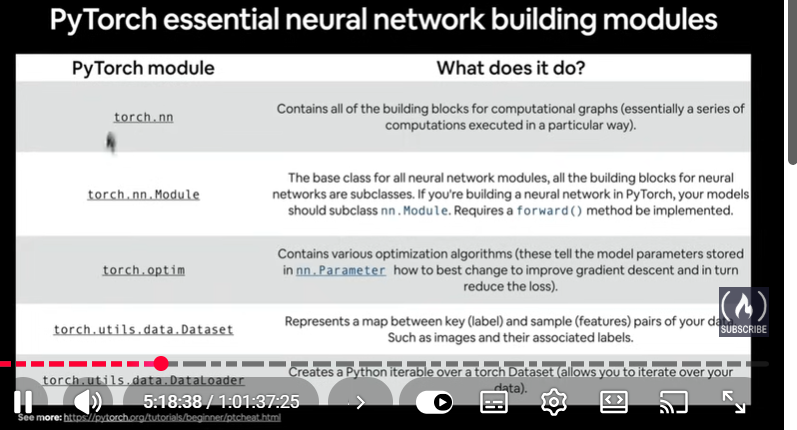

###  checking the contents of our pytorch model


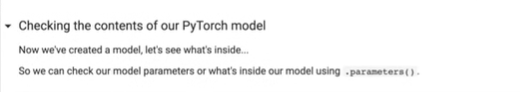

In [ ]:
torch.randn(1)

In [11]:
#create a random seed
torch.manual_seed(42)

#create an instance of the Modile
model_0=LinearRegressionModel()
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [12]:
model_0.parameters

<bound method Module.parameters of LinearRegressionModel()>

In [13]:
#List name parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [14]:
weight,bias #to reach here or near here

(0.7895, 0.058563)

#Making prediction using `torch.inference_mode()`

to check our models predictive powers, lets see how well it predicts y_test based on X_test.

when we pass data through our model its going to run forward method

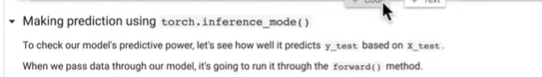

In [15]:
X_test,y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.6902],
         [0.7060],
         [0.7217],
         [0.7375],
         [0.7533],
         [0.7691],
         [0.7849],
         [0.8007],
         [0.8165],
         [0.8323]]))

In [16]:
#give same output as torch.infererence_mode one
y_preds=model_0(X_test)
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]], grad_fn=<AddBackward0>)

In [17]:
#Make prediction with Model
with torch.inference_mode():
  y_preds=model_0(X_test)


In [18]:
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [19]:
plot_prediction(X_train,y_train,X_test,y_test,y_preds)

NameError: name 'plot_prediction' is not defined

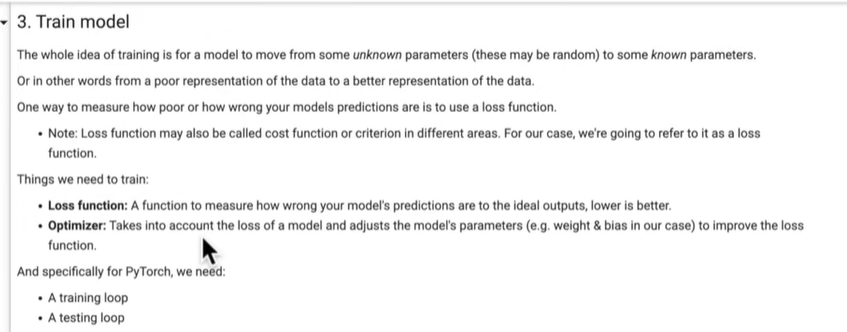

In [24]:
with torch.inference_mode():
  y_preds=model_0(X_test)

In [25]:
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [26]:
plot_prediction(X_train,y_train,X_test,y_test,y_preds)

NameError: name 'plot_prediction' is not defined

In [27]:
with torch.inference_mode():
  y_preds=model_0(X_test)

y_preds


#you can also do something with torch,no grad but torch.inference mdoe is preffered
with torch.no_grad():
  y_preds=model_0(X_test)

y_preds


tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

##. Train model

the whole idea of training is for model to move from some unknown parameters(these may be random) to some *known* parameters


or in simple word from poor representation to good representation

how pooor to measure how poor or how wrong your model is use loss function


* Note: Loss function may also be called cost function or criterion in different area, For our case we're going to refer to it as a loss function

* **Loss function** A function is measure how wrong your model's prediction is to real value

* **Optimizers** Takes into account the loss of models and adjust model
baiscally in our case to improve the loss function

and specifically for pytorch we need

* a training loop
* a testing loop

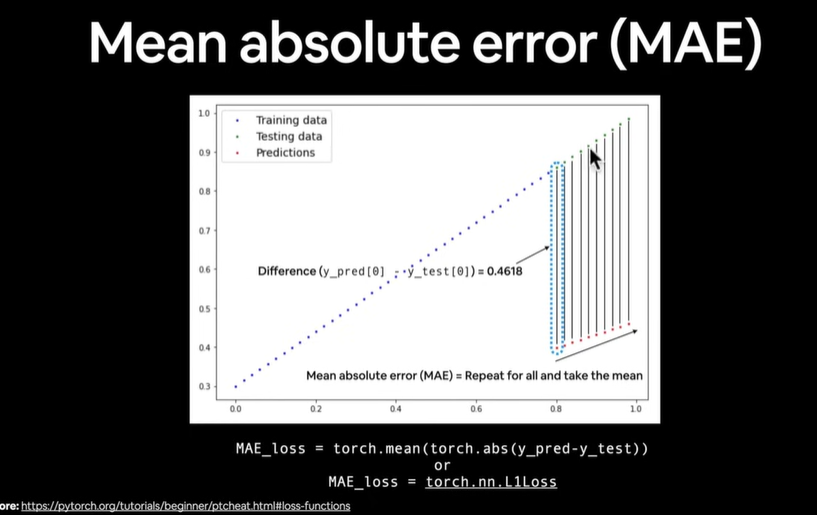


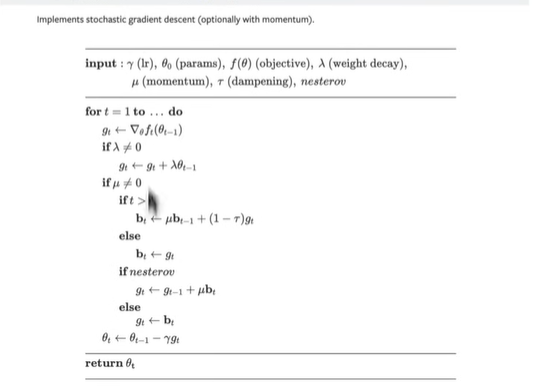

In [28]:
###Mean absolute error

## torch.nn.L1Loss (size,) ->mean absolute error


In [29]:
#Checking which parameters we have
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [30]:
#Setup a loss function

MAE_loss=torch.mean(torch.abs(y_preds-y_test))
MAE_loss

tensor(0.3328)

In [31]:
#Setup a loss function
loss_fn=nn.L1Loss()

#setup an optimizer(stochastic gradient descent)
optimizer=torch.optim.SGD(model_0.parameters(),
                          lr=0.007) #lr=learning rate=possibly the most important hyperparameter-> hyperparameter whcih you set manually

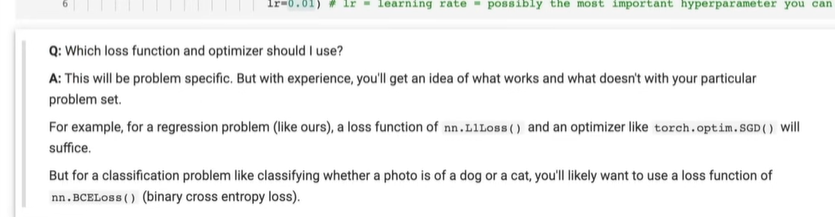

## building a training loop in pytorch

A couple of things we need a training loop:

0. Loop through data and do ...
1. Forward pass (this involves data moving through our model's `forward()` functions)-also called foward propogration
2. calculate the loss(compare forward pass prediction to ground truth labels)
3. Optimizer zero grad
4. Loss backward -move backwards though the network to calculate the gradient of each of parameter wrt to the loss(**backpropogation**)
5. Optimizer step-use the optimizer to adjust our model's parameter to try and improve the loss(**gradient**)

In [32]:
#an epoch is one loop through data..(this is hyperparameter as we set ourselves)

epochs=1000
##Training
#0. Loop though the data
for epoch in range(epochs):
  #set the model to training mode
  model_0.train() #train mode in Pytoch sets all parameters that require gradient to rquire gradient
  #1. Forward pass
  y_pred=model_0(X_train)
  #2. Calculate loss
  loss=loss_fn(y_pred,y_train)
  #3. Optimizer zero grad
  optimizer.zero_grad
  #4. perform backpropogation on the loss with respect to parameter of the model
  loss.backward()
  #5. Optimizer step
  optimizer.step()
  #by default how the optimizer changes will accumulate through the loop so... we have to zero them above in step 3





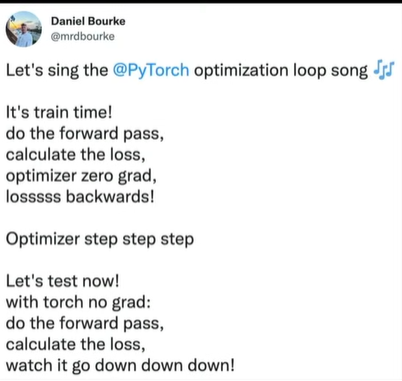
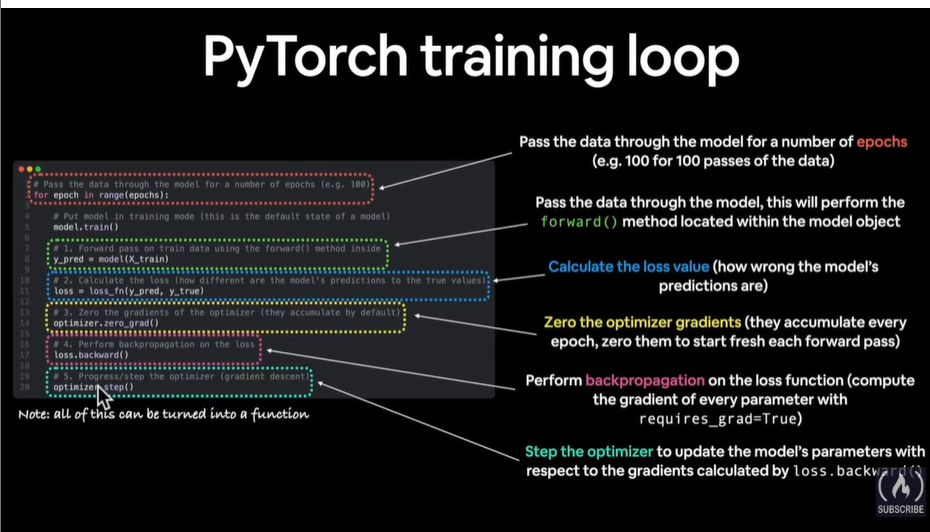

In [33]:
from numpy import test
#an epoch is one loop through data..(this is hyperparameter as we set ourselves)
torch.manual_seed(42)
epochs=101

#Track different values
epoch_count=[]
loss_values=[]
test_loss_values=[]

##Training
#0. Loop though the data
for epoch in range(epochs):

  #set the model to training mode
  model_0.train() #train mode in Pytoch sets all parameters that require gradient to rquire gradient

  #1. Forward pass
  y_pred=model_0(X_train)

  #2. Calculate loss
  loss=loss_fn(y_pred,y_train)
  print(f"Loss: {loss}")

  #3. Optimizer zero grad
  optimizer.zero_grad()

  #4. perform backpropogation on the loss with respect to parameter of the model
  loss.backward()

  #5. Optimizer step
  optimizer.step()

  ###Testing
  #by default how the optimizer changes will accumulate through the loop so... we have to zero them above in step 3
  model_0.eval()
  with torch.inference_mode():
    test_pred=model_0(X_test)
    test_loss=loss_fn(test_pred,y_test)

  if epoch%10==0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")
#Print out model state dict
    print(model_0.state_dict())

Loss: 0.06681409478187561
Epoch: 0 | Loss: 0.06681409478187561 | Test Loss: 0.18456287682056427
OrderedDict({'weights': tensor([1.1059]), 'bias': tensor([-0.0385])})
Loss: 0.0660238042473793
Loss: 0.065233513712883
Loss: 0.06444323807954788
Loss: 0.06374368816614151
Loss: 0.06313456594944
Loss: 0.06252545118331909
Loss: 0.061944492161273956
Loss: 0.0614812970161438
Loss: 0.06101809814572334
Loss: 0.06055491417646408
Epoch: 10 | Loss: 0.06055491417646408 | Test Loss: 0.15871331095695496
OrderedDict({'weights': tensor([1.0883]), 'bias': tensor([-0.0486])})
Loss: 0.06009172275662422
Loss: 0.05967556685209274
Loss: 0.059322334825992584
Loss: 0.05896909162402153
Loss: 0.058615852147340775
Loss: 0.058262623846530914
Loss: 0.05790940672159195
Loss: 0.05758584290742874
Loss: 0.05730583518743515
Loss: 0.057025838643312454
Epoch: 20 | Loss: 0.057025838643312454 | Test Loss: 0.14251239597797394
OrderedDict({'weights': tensor([1.0732]), 'bias': tensor([-0.0514])})
Loss: 0.05674584582448006
Loss: 0

In [34]:
print(f"Real weight: {weight} and Real Bias: {bias}",)

Real weight: 0.7895 and Real Bias: 0.058563


In [35]:
print(model_0.state_dict())

OrderedDict({'weights': tensor([0.9744]), 'bias': tensor([-0.0189])})


In [36]:
with torch.inference_mode():
    y_preds_test = model_0(X_test)

plot_prediction(prediction=y_preds_test)
#So my first dl model prediction is good and i change our weight and bias true many times it predicted it accurately but not precisely

NameError: name 'plot_prediction' is not defined